In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

folder = Path.cwd()
years = [2015, 2020, 2025]

print("Folder:", folder)

Folder: D:\1_Rupanarayan Sahu\Geo AI\Day_20\Day_20


In [2]:
lst = {}
ndvi = {}

for year in years:
    with rasterio.open(folder / f"Goa_LST_{year}.tif") as src:
        lst[year] = src.read(1, masked=True).astype("float32")

    with rasterio.open(folder / f"Goa_NDVI_{year}.tif") as src:
        ndvi[year] = src.read(1, masked=True).astype("float32")

print("All six rasters loaded.")

All six rasters loaded.


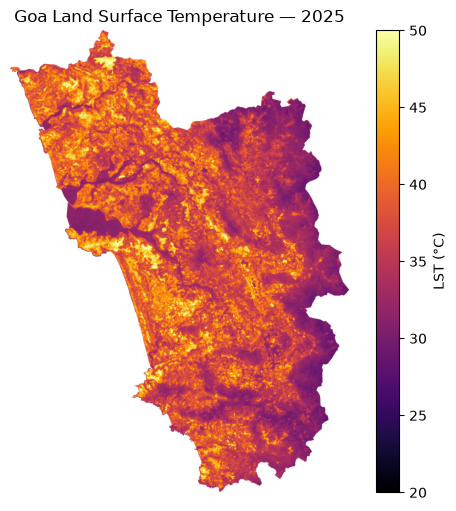

In [3]:
plt.figure(figsize=(7, 6))

plt.imshow(lst[2025], cmap="inferno", vmin=20, vmax=50)
plt.colorbar(label="LST (°C)")
plt.title("Goa Land Surface Temperature — 2025")
plt.axis("off")

plt.show()

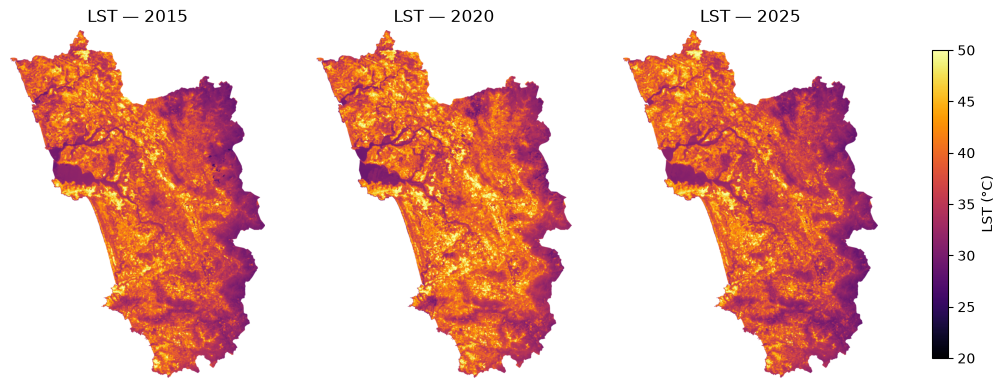

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, year in zip(axes, years):
    image = ax.imshow(lst[year], cmap="inferno", vmin=20, vmax=50)
    ax.set_title(f"LST — {year}")
    ax.axis("off")

fig.colorbar(image, ax=axes, label="LST (°C)", shrink=0.8)
plt.show()

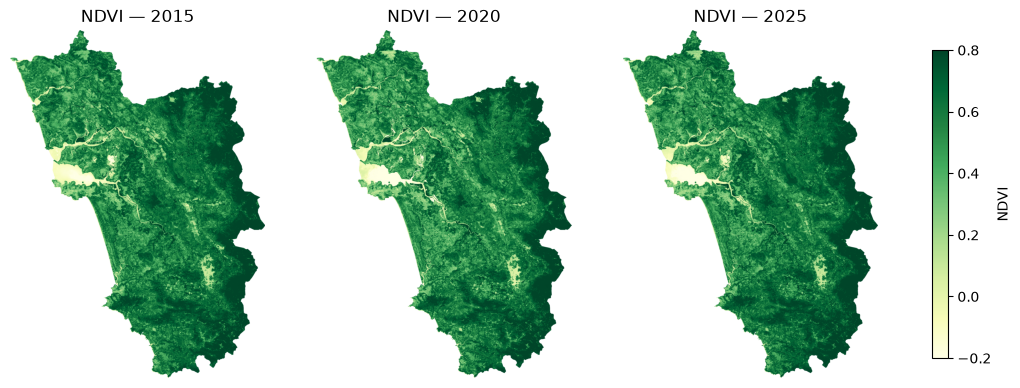

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, year in zip(axes, years):
    image = ax.imshow(ndvi[year], cmap="YlGn", vmin=-0.2, vmax=0.8)
    ax.set_title(f"NDVI — {year}")
    ax.axis("off")

fig.colorbar(image, ax=axes, label="NDVI", shrink=0.8)
plt.show()

In [6]:
rows = []

for year in years:
    for name, raster in [("LST", lst[year]), ("NDVI", ndvi[year])]:
        values = raster.compressed()
        values = values[np.isfinite(values)]

        rows.append({
            "Year": year,
            "Variable": name,
            "Mean": np.mean(values),
            "Median": np.median(values),
            "Std_Dev": np.std(values),
            "Minimum": np.min(values),
            "Maximum": np.max(values),
            "Valid_Pixels": len(values)
        })

stats = pd.DataFrame(rows).round(3)
display(stats)
stats.to_csv(folder / "Goa_LST_NDVI_Statistics.csv", index=False)
print("Statistics saved to Goa_LST_NDVI_Statistics.csv")

,Year,Variable,Mean,Median,Std_Dev,Minimum,Maximum,Valid_Pixels
0,2015,LST,37.351002,37.109001,4.249,23.320,64.903999,4295802
1,2015,NDVI,0.592000,0.634000,0.196,-0.496,0.911000,4295913
2,2020,LST,38.625000,38.457001,4.453,22.410,66.405998,4295798
3,2020,NDVI,0.568000,0.606000,0.210,-0.606,0.905000,4295909
4,2025,LST,36.938000,36.629002,4.241,27.899,62.875999,4295802
5,2025,NDVI,0.594000,0.638000,0.200,-0.410,0.892000,4295913


Statistics saved to Goa_LST_NDVI_Statistics.csv


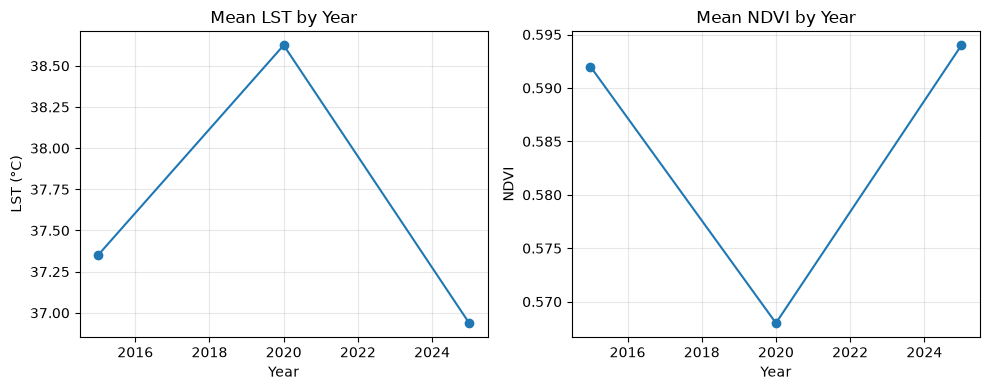

In [7]:
means = stats.pivot(index="Year", columns="Variable", values="Mean")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(means.index, means["LST"], marker="o")
axes[0].set_title("Mean LST by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("LST (°C)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(means.index, means["NDVI"], marker="o")
axes[1].set_title("Mean NDVI by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("NDVI")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Difference maps: 2025 minus 2015
**Formula:** change = value in 2025 − value in 2015.

Positive LST change means a higher surface temperature in 2025. Negative LST change means a lower value. Positive NDVI change indicates increased greenness; negative NDVI change indicates decreased greenness.

The code below uses only pixels valid in both years.

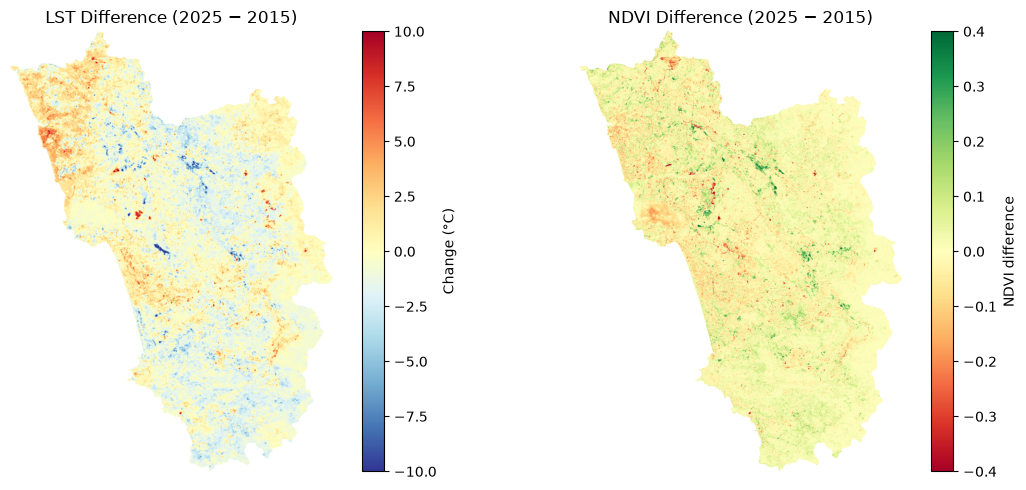

In [8]:
def difference_map(raster_2015, raster_2025):
    first = raster_2015.filled(np.nan)
    last = raster_2025.filled(np.nan)

    valid = np.isfinite(first) & np.isfinite(last)
    difference = np.full(first.shape, np.nan, dtype="float32")
    difference[valid] = last[valid] - first[valid]

    return difference

lst_change = difference_map(lst[2015], lst[2025])
ndvi_change = difference_map(ndvi[2015], ndvi[2025])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

image1 = axes[0].imshow(lst_change, cmap="RdYlBu_r", vmin=-10, vmax=10)
axes[0].set_title("LST Difference (2025 − 2015)")
axes[0].axis("off")
fig.colorbar(image1, ax=axes[0], label="Change (°C)")

image2 = axes[1].imshow(ndvi_change, cmap="RdYlGn", vmin=-0.4, vmax=0.4)
axes[1].set_title("NDVI Difference (2025 − 2015)")
axes[1].axis("off")
fig.colorbar(image2, ax=axes[1], label="NDVI difference")

plt.tight_layout()
plt.show()

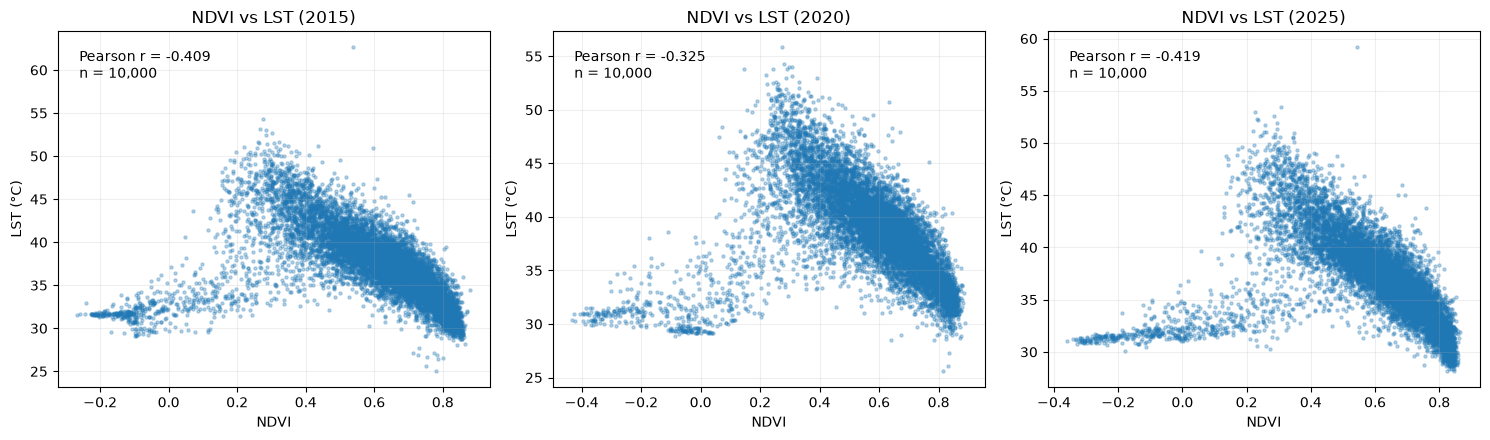

In [13]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, year in zip(axes, years):

    # Convert masked arrays to regular arrays
    lst_array = np.ma.asarray(lst[year])
    ndvi_array = np.ma.asarray(ndvi[year])

    # Check that both rasters have the same dimensions
    if lst_array.shape != ndvi_array.shape:
        raise ValueError(
            f"{year}: LST and NDVI raster dimensions differ. "
            "Align the rasters before plotting."
        )

    # Create one common mask for valid pixels
    lst_data = np.asarray(lst_array.data)
    ndvi_data = np.asarray(ndvi_array.data)

    valid = (
        ~np.ma.getmaskarray(lst_array)
        & ~np.ma.getmaskarray(ndvi_array)
        & np.isfinite(lst_data)
        & np.isfinite(ndvi_data)
    )

    # Extract corresponding pixels
    x_all = ndvi_data[valid]
    y_all = lst_data[valid]

    if len(x_all) < 2:
        ax.set_title(f"{year}: Insufficient valid pixels")
        continue

    # Randomly sample up to 10,000 pixels
    rng = np.random.default_rng(42)
    n = min(10000, len(x_all))
    indices = rng.choice(len(x_all), size=n, replace=False)

    x = x_all[indices]
    y = y_all[indices]

    # Calculate Pearson correlation
    correlation = np.corrcoef(x, y)[0, 1]

    # Plot scatter points
    ax.scatter(x, y, s=5, alpha=0.3)

    ax.set_title(f"NDVI vs LST ({year})")
    ax.set_xlabel("NDVI")
    ax.set_ylabel("LST (°C)")
    ax.grid(alpha=0.2)

    ax.text(
        0.05, 0.95,
        f"Pearson r = {correlation:.3f}\nn = {n:,}",
        transform=ax.transAxes,
        va="top"
    )

plt.tight_layout()
plt.show()
